In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pints
import pints.io
import pints.plot
import scipy.interpolate
from collections import defaultdict
import matplotlib

import mechanistic_model
import likelihood

In [2]:
df = pd.read_csv('data/df_covariates_better_date.csv')

df["weight2"] = df["weight"] ** 2

In [3]:
X_a = df[["f.acc_condH",
          "f.acc_condM",
          "f.acc_condT", 
          "f.exp_condH",
          "f.exp_condM",
          "f.exp_condT",
          "f.week6",
          "f.acc_condH:f.week6",
          "f.acc_condM:f.week6",
          "f.acc_condT:f.week6"
]]
X_a.insert(0, 'Ones', 1) 

X_h = df[["weight", "weight2",]]
X_h.insert(0, 'Ones', 1)

ids = df["fish.id"]

ns_prey_eaten = df["n_prey_eaten"]
ns_prey_initial = df["n_prey_initial"]

# likelihood for a particular parameter set
beta = np.zeros(X_a.shape[1])
gamma = np.zeros(X_h.shape[1])

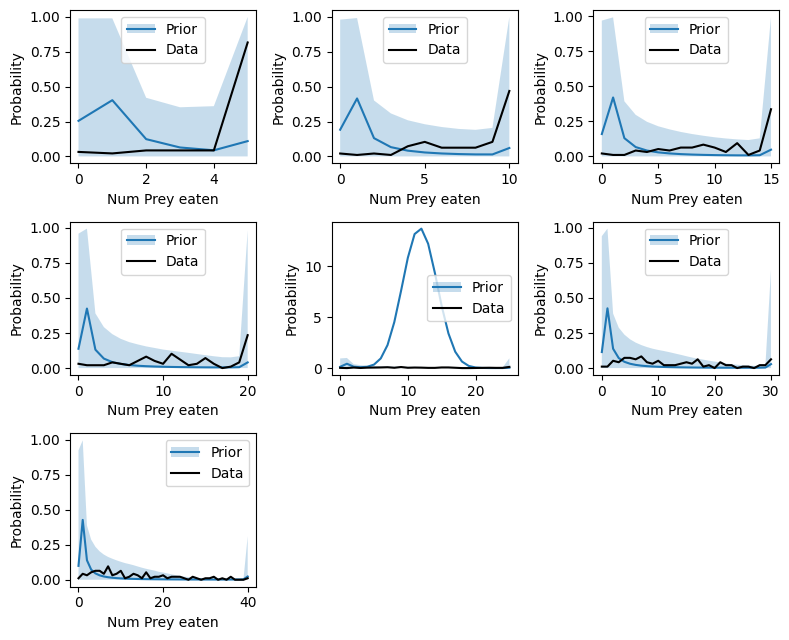

In [9]:
# Prior Predictive

dists = defaultdict(list)
data_dists = defaultdict(list)

as_observed = []
hs_observed = []
ns_prey_eaten_observed = []

prior = pints.MultivariateGaussianLogPrior([0] * p.n_parameters(), 3.0 * np.identity(p.n_parameters()))

prior_samples = prior.sample(1000)

for x in prior_samples:

    for n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):
        
        beta = x[:len(beta)]
        gamma = x[len(beta):]
        a = likelihood.a_parameter_creator(beta, x_a)
        r = likelihood.a_parameter_creator(gamma, x_h)
        
        p_eaten = mechanistic_model.solve_system_simple_h_simplex(n_prey_initial, a, r)
        as_observed.append(a)
        hs_observed.append(r)
        ns_prey_eaten_observed.append(n_prey_initial)
        dists[n_prey_initial].append(np.asarray(p_eaten))
        data = [0] * (n_prey_initial + 1)
        data[n_prey_eaten] = 1
        data_dists[n_prey_initial].append(np.asarray(data))

ns = sorted(list(set(ns_prey_initial)))

fig = plt.figure(figsize=(8, 6.5))

for i, n in enumerate(ns):
    ax = fig.add_subplot(3, 3, i+1)
    
    m = dists[n]
    d = data_dists[n]

    x = np.arange(n+1)
    l1, = ax.plot(x, np.mean(m, axis=0), label='Inferred')
    p1 = ax.fill_between(x, np.percentile(m, 2.5, axis=0), np.percentile(m, 97.5, axis=0), alpha=0.25)

    l2, = ax.plot(x, np.mean(d, axis=0), color='k', label='Data')

    ax.legend(((l1, p1), l2), ['Prior', 'Data'])

    ax.set_xlabel('Num Prey eaten')
    ax.set_ylabel('Probability')


fig.set_tight_layout(True)
plt.show()


Text(0, 0.5, '$10^{+1}$')

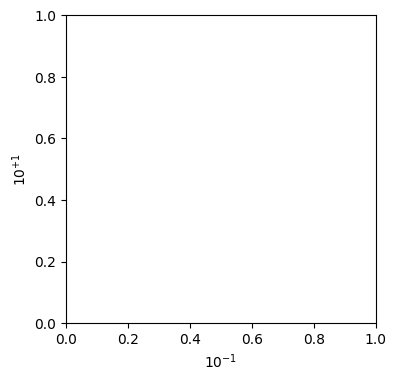

In [12]:
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlabel(r'$10^{-1}$')
ax.set_ylabel(r'$10^{+1}$')

In [5]:
class Likelihood(pints.LogPDF):
    def __init__(self, ns_prey_eaten, ns_prey_initial, X_a, X_h, n_beta, n_gamma):
        super().__init__()
        self.ns_prey_eaten = ns_prey_eaten
        self.ns_prey_initial = ns_prey_initial

        self.X_a = X_a
        self.X_h = X_h

        self.n_beta = n_beta
        self.n_gamma = n_gamma

    def __call__(self, x):
        beta = x[:self.n_beta]
        gamma = x[self.n_beta:]

        return mechanistic_model.log_likelihood_all_fish(ns_prey_eaten, ns_prey_initial, beta, gamma, X_a, X_h)
    
    def n_parameters(self):
        return self.n_beta + self.n_gamma


p = Likelihood(ns_prey_eaten, ns_prey_initial, X_a, X_h, len(beta), len(gamma))

prior = pints.MultivariateGaussianLogPrior([0] * p.n_parameters(), 1.0 * np.identity(p.n_parameters()))

posterior = pints.LogPosterior(p, prior)

best_opt_result = -np.inf
best_opt_x = -1
for i in range(10):
    opt = pints.OptimisationController(
        posterior,
        prior.sample(),
        method=pints.CMAES,
    )
    opt.set_max_iterations(400)
    x, err = opt.run()
    if err > best_opt_result:
        best_opt_x = np.copy(x)
        best_opt_result = err
    
x = best_opt_x

mcmc = pints.MCMCController(
    posterior,
    3,
    [best_opt_x,best_opt_x, best_opt_x],
    method=pints.HaarioBardenetACMC,
)

mcmc.set_max_iterations(50000)


mcmc.set_chain_filename('run1_noyear_opt_weight2.csv')

chains_opt = mcmc.run()



Maximising LogPDF
Using Covariance Matrix Adaptation Evolution Strategy (CMA-ES)
Running in sequential mode.
Population size: 11
Iter. Eval.  Best      Current   Time m:s
0     11     -12669.33 -12669.33   0:00.8
1     22     -12632.71 -12632.71   0:01.5

----------------------------------------
Unexpected termination.
Current score: -12632.70637269587
Current position:
-3.19959796246224726e-01
 6.47964625455247134e-01
-1.00412518764769643e+00
 2.89939607479299477e-01
-5.58274557910168889e-02
-3.52778603412431502e-01
-1.11504289374394117e+00
 6.43036307267954133e-01
 8.74002896256301232e-01
-1.83859505109491395e-01
-2.25710041593421007e-01
-1.84503233031379388e-01
-1.80674497849770765e+00
-8.53460555264642817e-01
----------------------------------------
Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/opt/anaconda3/envs/stan_env2/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3549, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/3m/pbjjgnm122x826md7g0r6yr00000gn/T/ipykernel_9614/284973018.py", line 38, in <module>
    x, err = opt.run()
             ^^^^^^^^^
  File "/opt/anaconda3/envs/stan_env2/lib/python3.11/site-packages/pints/_optimisers/__init__.py", line 649, in run
    fs = evaluator.evaluate(xs)
         ^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/envs/stan_env2/lib/python3.11/site-packages/pints/_evaluation.py", line 119, in evaluate
    return self._evaluate(positions)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/envs/stan_env2/lib/python3.11/site-packages/pints/_evaluation.py", line 481, in _evaluate
    scores[k] = self._function(x, *self._args)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/envs/stan_env2/lib/python3.11/site-p

In [10]:
params = [ "intercept_a",
          "f.acc_condH_a",
          "f.acc_condM_a",
          "f.acc_condT_a", 
          "f.exp_condH_a",
          "f.exp_condM_a",
          "f.exp_condT_a",
          "f.week6_a",
          "f.acc_condH:f.week6_a",
          "f.acc_condM:f.week6_a",
          "f.acc_condT:f.week6_a",
          "intercept_h",
          "weight_h",
          "weight_h^2"
]

In [16]:
for chain in range(3):
    df = pd.DataFrame({param: chains_opt[chain, :, i] for i, param in enumerate(params)})
    df.to_csv('chains_h_weight_a_other_chain{}.csv'.format(chain), index=False)

In [ ]:
params = [ "intercept_a",
          "f.acc_condH_a",
          "f.acc_condM_a",
          "f.acc_condT_a", 
          "f.exp_condH_a",
          "f.exp_condM_a",
          "f.exp_condT_a",
          "f.week6_a",
          "f.acc_condH:f.week6_a",
          "f.acc_condM:f.week6_a",
          "f.acc_condT:f.week6_a",
          "intercept_h",
          "weight_h",
          "weight_h^2"
]

for chain in range(1):
    df = pd.DataFrame({param: chains_opt[chain, :, i] for i, param in enumerate(params)})
    df.to_csv('opt_results2_chain{}.csv'.format(chain), index=False)

In [11]:
df = []


for fish_id, n_prey_eaten, n_prey_initial, x_a, x_h in zip(
ids, ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
):
    for i, x in enumerate(chains_opt[0, 25000::500, :]):

        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        a = fastprey.likelihood.a_parameter_creator(beta, x_a)
        r = fastprey.likelihood.a_parameter_creator(gamma, x_h)
        
        p_eaten = fastprey.mechanistic_model.solve_system_simple_h_simplex(n_prey_initial, a, r)

        p_eaten = list(p_eaten)

        if len(p_eaten) < 41:
            p_eaten = p_eaten + [0] * (41-len(p_eaten))

        p_eaten = np.asarray(p_eaten)

        df.append([fish_id, n_prey_initial, n_prey_eaten, i,] + list(p_eaten))

df = np.asarray(df)

df = pd.DataFrame(df, columns=['fish_id', 'n_prey_initial', 'n_prey_eaten', 'mcmc_iteration',] + ['posterior_p_{}'.format(i) for i in range(41)])
        

In [75]:
df

,fish_id,n_prey_initial,n_prey_eaten,mcmc_iteration,posterior_p_0,posterior_p_1,posterior_p_2,posterior_p_3,posterior_p_4,posterior_p_5,...,posterior_p_31,posterior_p_32,posterior_p_33,posterior_p_34,posterior_p_35,posterior_p_36,posterior_p_37,posterior_p_38,posterior_p_39,posterior_p_40
0,85.0,5.0,5.0,0.0,5.660747e-21,0.001537,0.012948,0.056667,0.190537,0.738311,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1,85.0,5.0,5.0,1.0,5.248651e-21,0.002037,0.016190,0.066433,0.205854,0.709486,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2,85.0,5.0,5.0,2.0,9.772135e-35,0.001782,0.013034,0.048796,0.136240,0.800148,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
3,85.0,5.0,5.0,3.0,9.870218e-31,0.001523,0.011710,0.046318,0.138955,0.801494,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
4,85.0,5.0,5.0,4.0,4.261198e-27,0.001855,0.014097,0.055110,0.163255,0.765683,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133595,752.0,40.0,21.0,195.0,0.000000e+00,0.000003,0.000043,0.000273,0.001148,0.003616,...,0.000011,0.000004,1.634389e-06,6.043363e-07,2.158275e-07,7.440086e-08,2.472184e-08,7.897935e-09,2.423128e-09,8.522627e-10
133596,752.0,40.0,21.0,196.0,0.000000e+00,0.000003,0.000043,0.000271,0.001140,0.003592,...,0.000011,0.000004,1.696859e-06,6.300650e-07,2.260883e-07,7.836791e-08,2.621045e-08,8.440821e-09,2.616468e-09,9.493920e-10
133597,752.0,40.0,21.0,197.0,0.000000e+00,0.000004,0.000049,0.000304,0.001266,0.003947,...,0.000009,0.000003,1.303978e-06,4.754708e-07,1.673456e-07,5.680606e-08,1.856595e-08,5.824258e-09,1.749725e-09,5.884017e-10
133598,752.0,40.0,21.0,198.0,0.000000e+00,0.000004,0.000044,0.000278,0.001166,0.003669,...,0.000010,0.000004,1.487955e-06,5.442668e-07,1.919890e-07,6.524031e-08,2.131045e-08,6.665642e-09,1.989056e-09,6.461304e-10


In [12]:
df.to_csv('posterior_samples_h_weight_a_other_weight2.csv')

In [14]:
all_lls = []

for x in chains_opt[0, 25000::500, :]:
    lls = []

    for n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):   
        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        ll = fastprey.mechanistic_model.log_likelihood_single_fish(n_prey_eaten, n_prey_initial, beta, gamma, x_a, x_h)
        lls.append(ll)
    
    all_lls.append(lls)

all_lls = np.asarray(all_lls)

In [15]:
np.savetxt('samples_ll_h_weight_a_other_weight2.csv', all_lls)

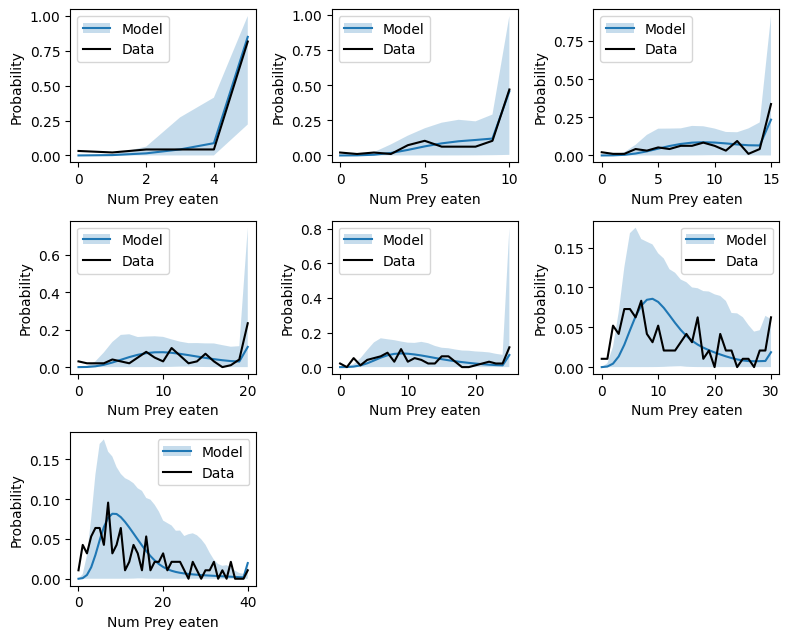

In [ ]:
dists = defaultdict(list)
data_dists = defaultdict(list)

ids_observed = []
as_observed = []
hs_observed = []
ns_prey_eaten_observed = []

for x in chains_opt[0, 25000::500, :]:

    for fish_id, n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ids, ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):
        
        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        a = fastprey.likelihood.a_parameter_creator(beta, x_a)
        r = fastprey.likelihood.a_parameter_creator(gamma, x_h)
        
        p_eaten = fastprey.mechanistic_model.solve_system_simple_h_simplex(n_prey_initial, a, r)
        
        ids_observed.append(fish_id)
        as_observed.append(a)
        hs_observed.append(r)
        ns_prey_eaten_observed.append(n_prey_initial)
        dists[n_prey_initial].append(np.asarray(p_eaten))
        data = [0] * (n_prey_initial + 1)
        data[n_prey_eaten] = 1
        data_dists[n_prey_initial].append(np.asarray(data))

ns = sorted(list(set(ns_prey_initial)))

fig = plt.figure(figsize=(8, 6.5))

for i, n in enumerate(ns):
    ax = fig.add_subplot(3, 3, i+1)
    
    m = dists[n]
    d = data_dists[n]

    x = np.arange(n+1)
    l1, = ax.plot(x, np.mean(m, axis=0), label='Inferred')
    p1 = ax.fill_between(x, np.percentile(m, 5, axis=0), np.percentile(m, 95, axis=0), alpha=0.25)

    l2, = ax.plot(x, np.mean(d, axis=0), color='k', label='Data')

    ax.legend(((l1, p1), l2), ['Model', 'Data'])

    ax.set_xlabel('Num Prey eaten')
    ax.set_ylabel('Probability')



fig.set_tight_layout(True)
plt.show()




In [39]:
for i, n in enumerate(ns):
    
    m = dists[n]
    d = data_dists[n]

    x = np.arange(n+1)
    mean = np.mean(m, axis=0)
    lower = np.percentile(m, 5, axis=0)
    upper = np.percentile(m, 95, axis=0)
    data = np.mean(d, axis=0)

    df = pd.DataFrame({'num prey': x, 'mean': mean, 'lower': lower, 'upper': upper, 'data': data})

    df.to_csv('run2_posterior.csv'.format(n))

In [ ]:
all_lls = []

for x in chains_opt[0, 5000::25, :]:
    lls = []

    for n_prey_eaten, n_prey_initial, x_a, x_h in zip(
    ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_h.to_numpy()
    ):   
        beta = x[:p.n_beta]
        gamma = x[p.n_beta:]
        ll = mechanistic_model.log_likelihood_single_fish(n_prey_eaten, n_prey_initial, beta, gamma, x_a, x_h)
        lls.append(ll)
    
    all_lls.append(lls)

all_lls = np.asarray(all_lls)

In [32]:
np.savetxt('run2_ll.csv', all_lls)

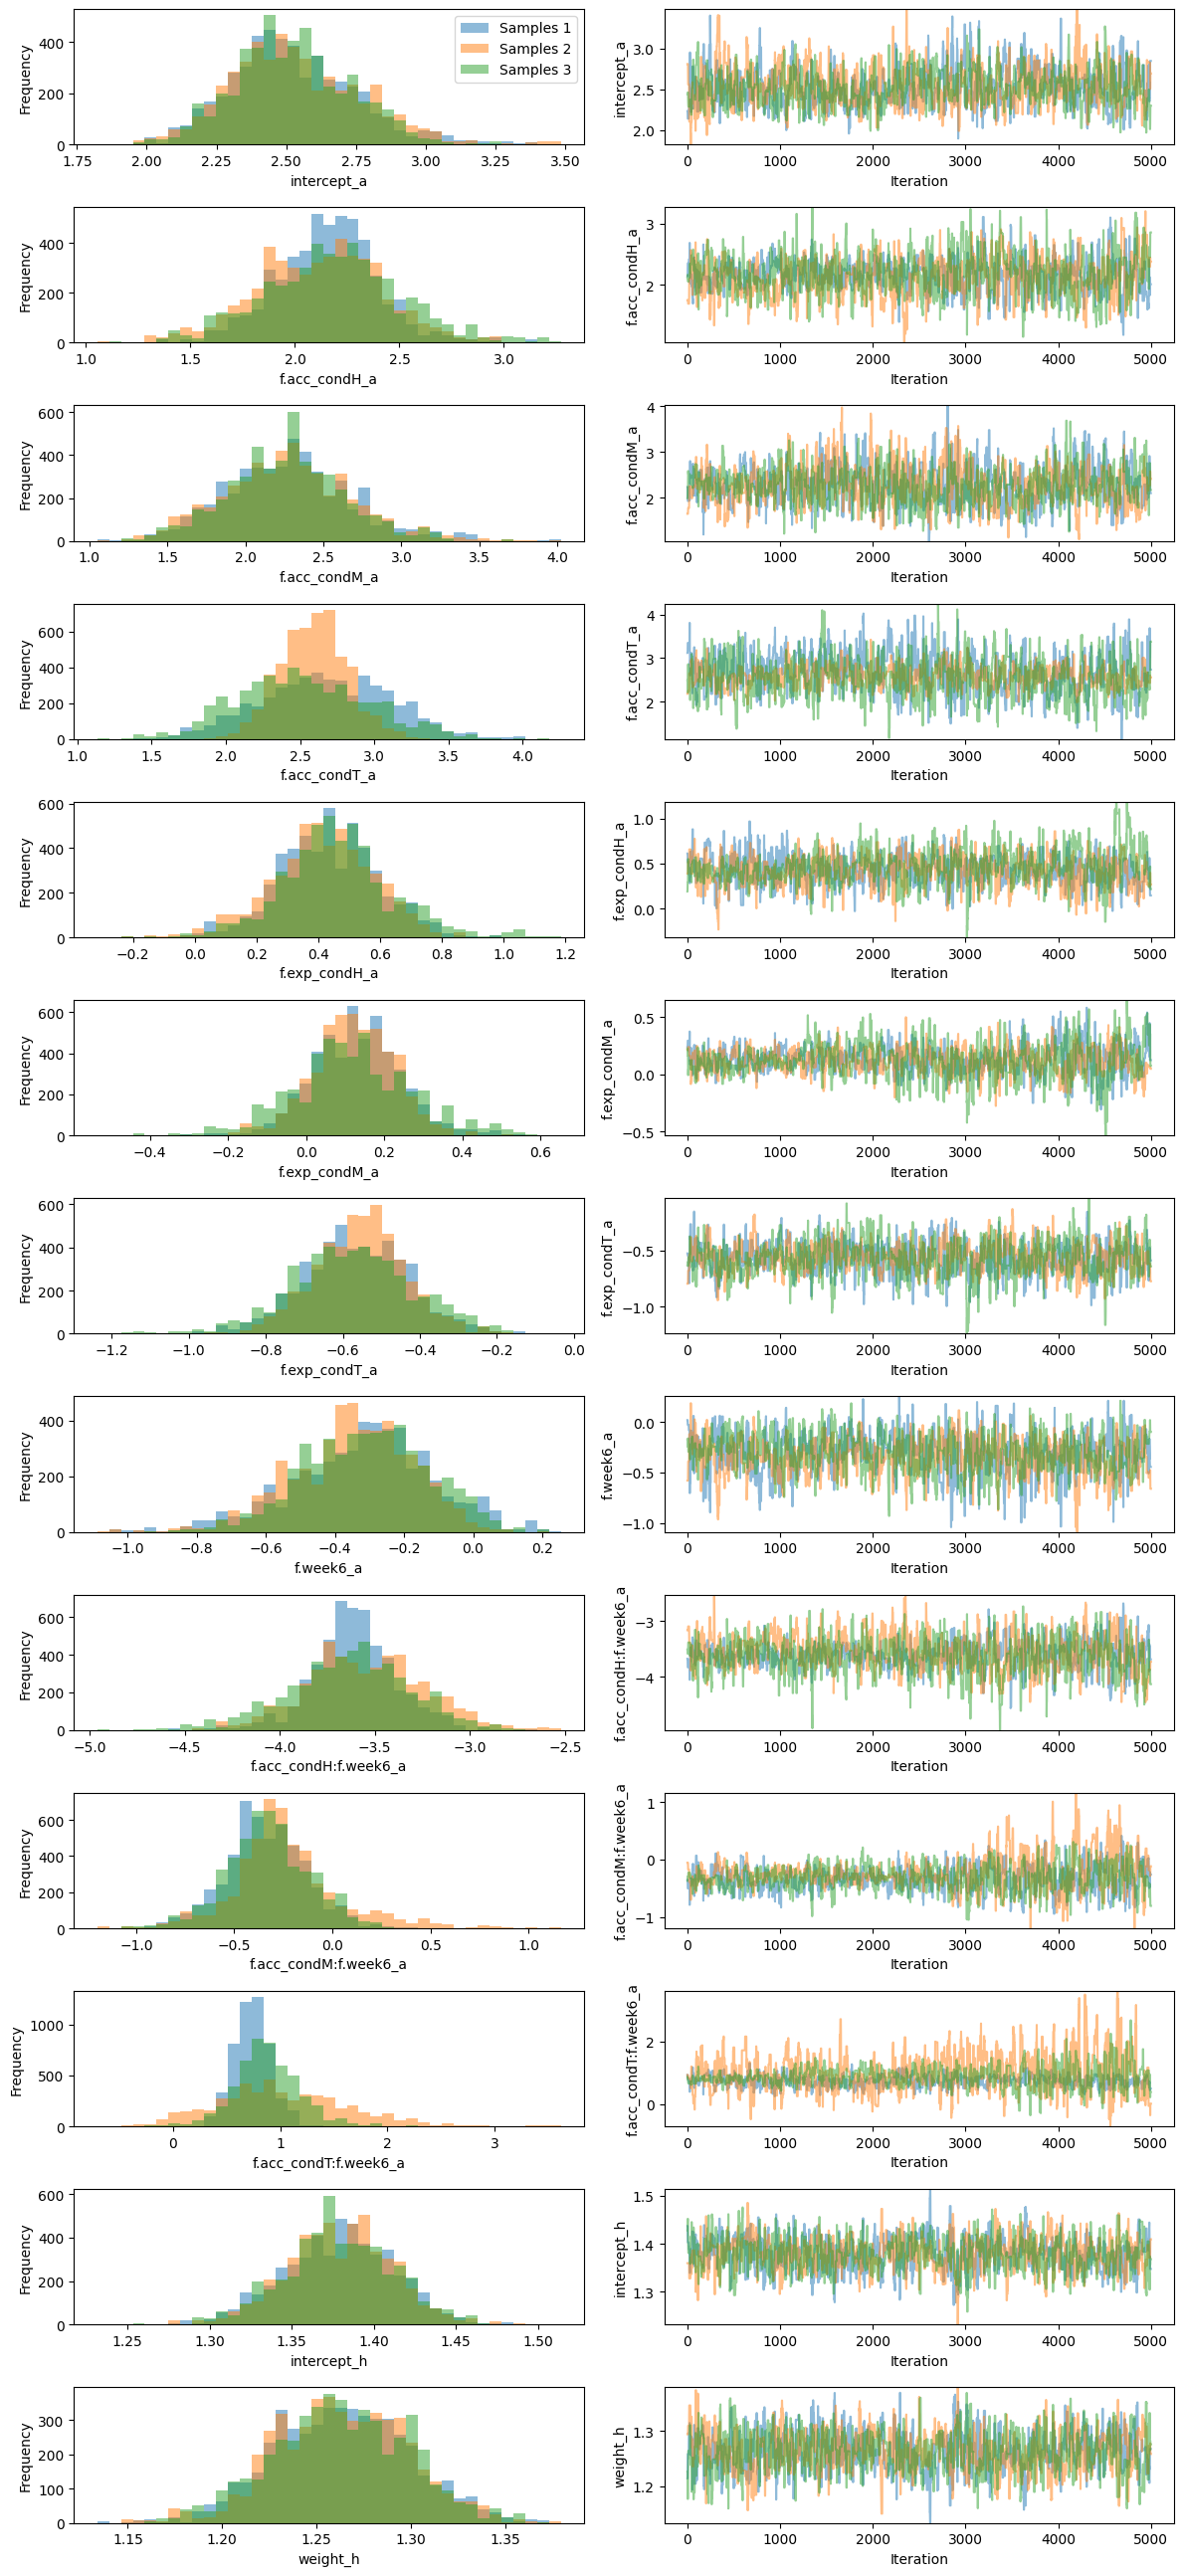

In [25]:
params = [ "intercept_a",
          "f.acc_condH_a",
          "f.acc_condM_a",
          "f.acc_condT_a", 
          "f.exp_condH_a",
          "f.exp_condM_a",
          "f.exp_condT_a",
          "f.week6_a",
          "f.acc_condH:f.week6_a",
          "f.acc_condM:f.week6_a",
          "f.acc_condT:f.week6_a",
          "intercept_h",
          "weight_h",
]

pints.plot.trace(chains_opt[:, 5000:, :], parameter_names = params)
plt.show()

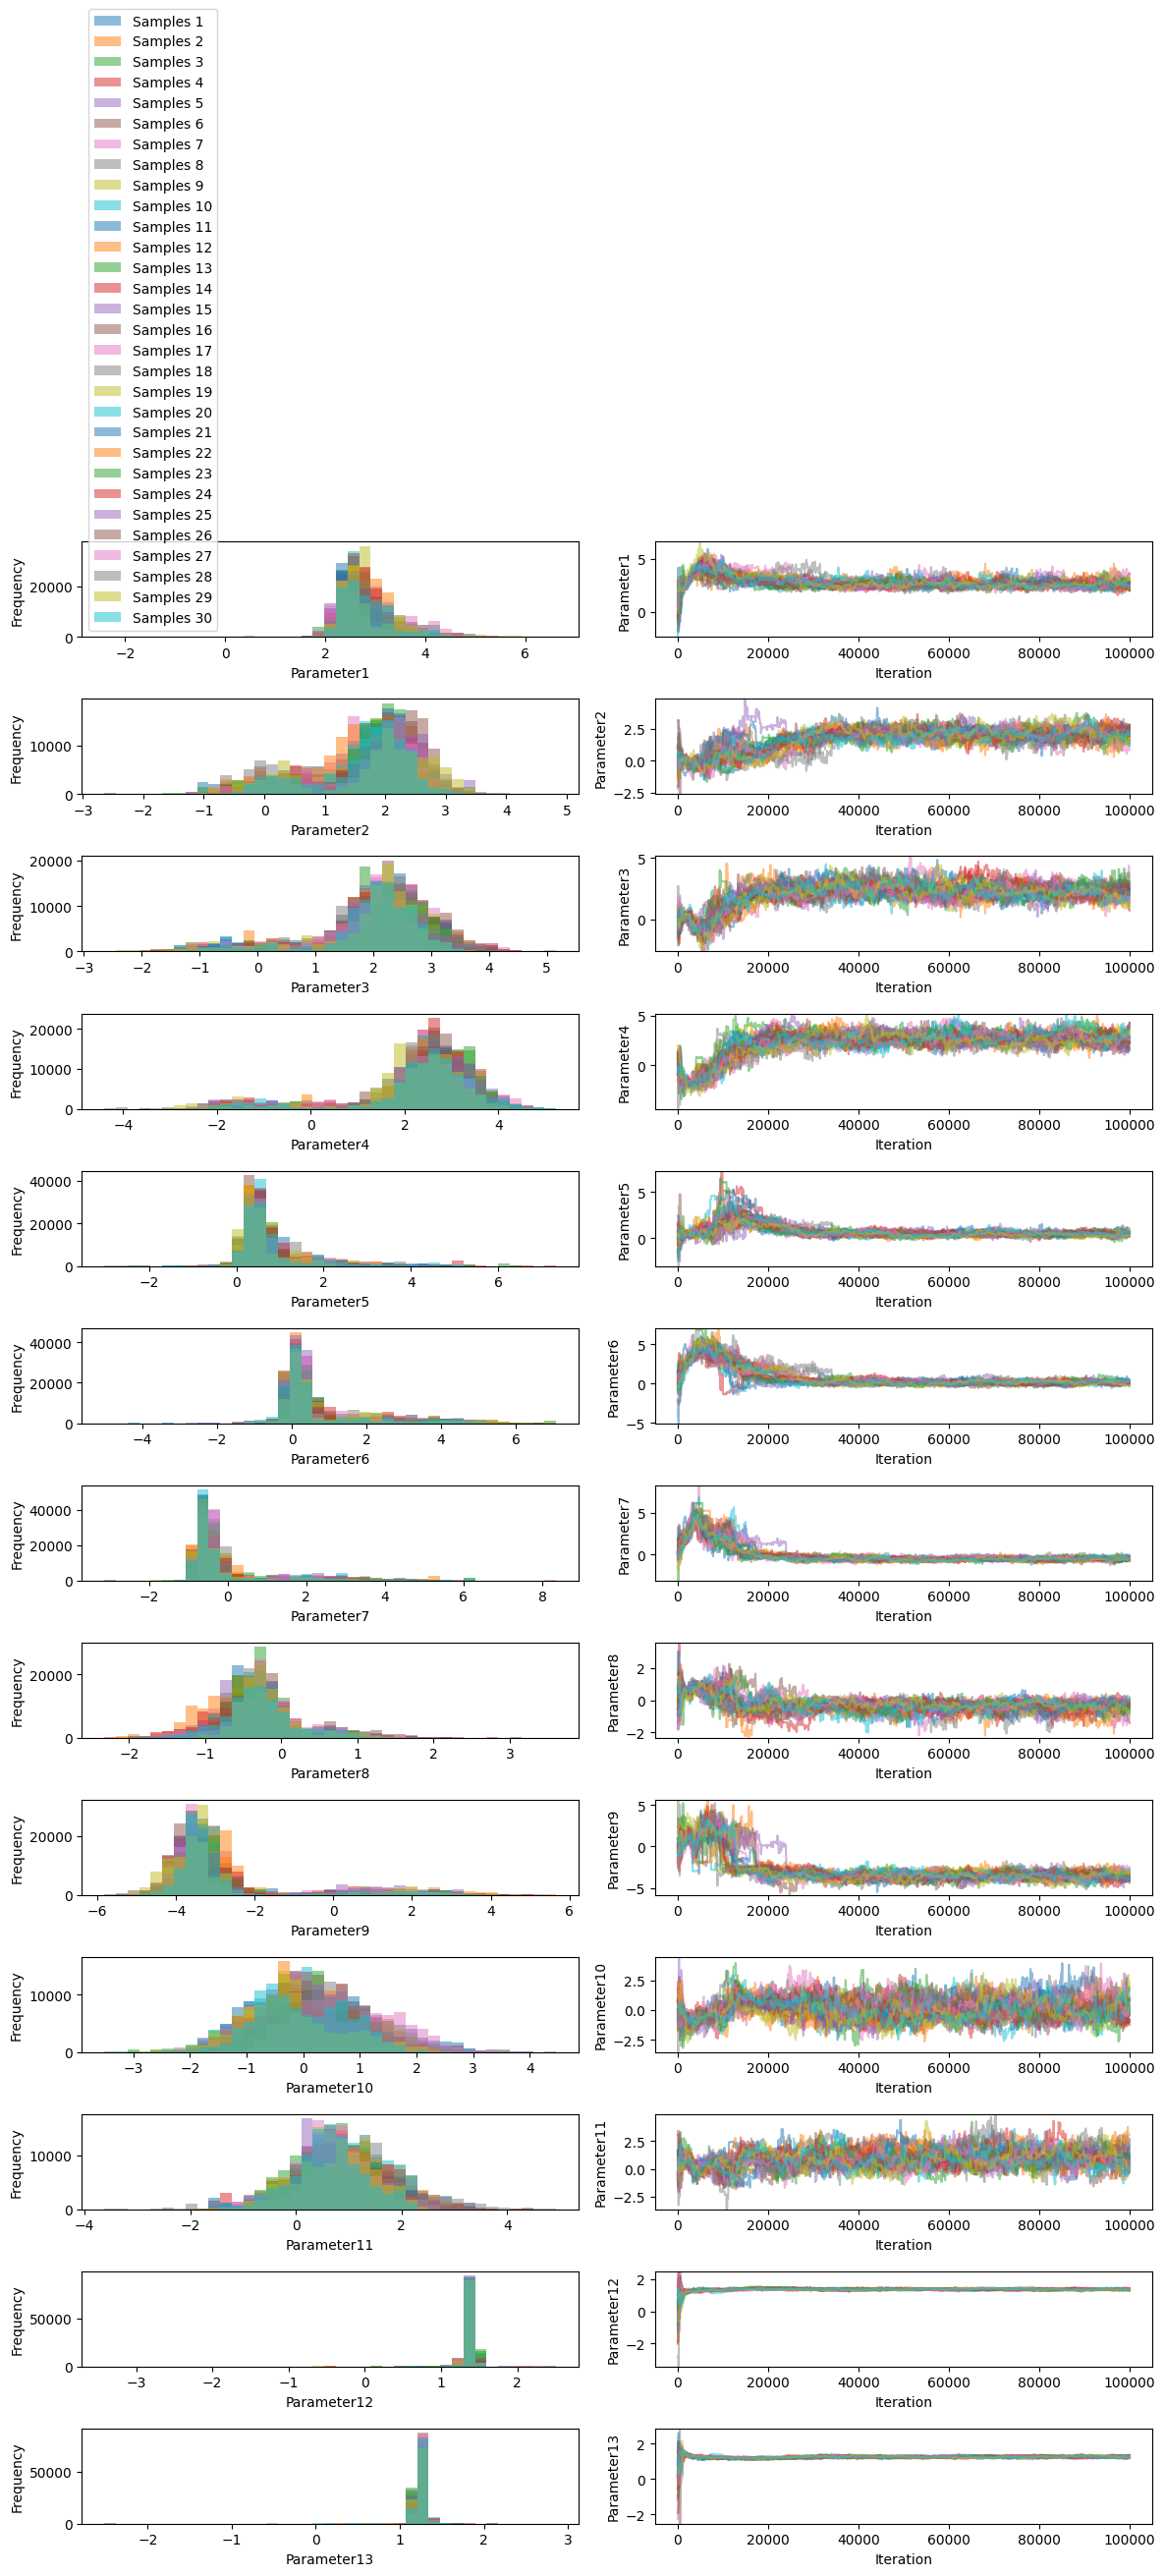

In [16]:
pints.plot.trace(chains)
plt.show()